In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display

AUDIO_SPLIT = "test"
VIDEO_SPLIT = "val"

ROOT = next(
    (p for candidate in (Path.cwd(), *Path.cwd().parents)
       if (p := candidate.resolve()).joinpath("Audio", "results").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Project root not found: Audio/results/ is required.")

RESULTS = ROOT / "Audio" / "results"
OUTPUT = RESULTS / "presentation_figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

NAVY = "#183153"
BLUE = "#2563EB"
TEAL = "#0F766E"
GREY = "#64748B"
ORANGE = "#D97706"
LIGHT = "#E6EDF5"
DARK = "#1F2937"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})

def read_csv(relative):
    path = RESULTS / relative
    if not path.is_file():
        raise FileNotFoundError(f"Saved results not found: {path}")
    return pd.read_csv(path)

def save_pdf(fig, name):
    path = OUTPUT / name
    fig.savefig(path, format="pdf", bbox_inches="tight", pad_inches=0.13)
    print("Saved:", path.relative_to(ROOT))
    plt.show()
    plt.close(fig)

def clean(ax, grid_axis="y"):
    ax.grid(axis=grid_axis, alpha=0.18, linewidth=0.8)
    ax.set_axisbelow(True)

print("Project:", ROOT)
print("Figures:", OUTPUT.relative_to(ROOT))

Project: C:\Users\benja\Documents\CS_Master\Big Data at the Edge\Big_Data_at_the_Edge_Project
Figures: Audio\results\presentation_figures


Saved: Audio\results\presentation_figures\slide06_panns_early_exit_architecture.pdf


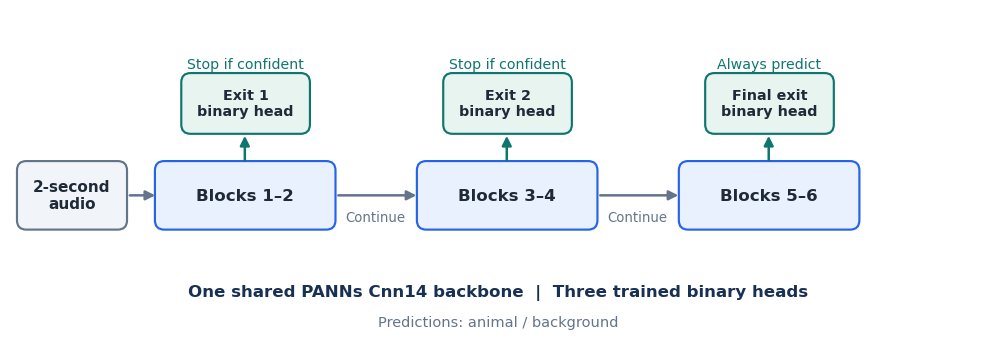

In [2]:
fig, ax = plt.subplots(figsize=(12.6, 4.4))
ax.set_xlim(0, 12.6)
ax.set_ylim(0, 4.35)
ax.axis("off")

def node(x, y, w, h, label, fc, ec, size=12, weight="bold", textcolor=DARK):
    patch = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.09,rounding_size=0.12",
                           linewidth=1.55, edgecolor=ec, facecolor=fc)
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, label, ha="center", va="center",
            fontsize=size, weight=weight, color=textcolor)

def arrow(a, b, color=GREY, lw=1.8):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14,
                                 linewidth=lw, color=color, shrinkA=2, shrinkB=2))

node(0.18, 1.61, 1.24, 0.70, "2-second\naudio", "#F1F5F9", GREY, size=11)
blocks = [(1.96, "Blocks 1--2"), (5.34, "Blocks 3--4"), (8.72, "Blocks 5--6")]
for x, label in blocks:
    node(x, 1.61, 2.15, 0.70, label.replace("--", "–"), "#EAF1FE", BLUE, size=12)

arrow((1.51, 1.96), (1.91, 1.96))
arrow((4.20, 1.96), (5.28, 1.96))
arrow((7.58, 1.96), (8.66, 1.96))
ax.text(4.72, 1.63, "Continue", ha="center", fontsize=9.5, color=GREY)
ax.text(8.10, 1.63, "Continue", ha="center", fontsize=9.5, color=GREY)

for x, title, footer in [(2.30, "Exit 1", "Stop if confident"),
                         (5.68, "Exit 2", "Stop if confident"),
                         (9.06, "Final exit", "Always predict")]:
    arrow((x + 0.73, 2.37), (x + 0.73, 2.76), color=TEAL)
    node(x, 2.84, 1.48, 0.60, title + "\nbinary head", "#E7F4EF", TEAL, size=10.3)
    ax.text(x + 0.74, 3.65, footer, ha="center", va="center", color=TEAL,
            fontsize=10.2, weight="medium")

ax.text(6.30, 0.66, "One shared PANNs Cnn14 backbone  |  Three trained binary heads",
        ha="center", fontsize=12, color=NAVY, weight="bold")
ax.text(6.30, 0.28, "Predictions: animal / background", ha="center", fontsize=10.5, color=GREY)
save_pdf(fig, "slide06_panns_early_exit_architecture.pdf")

Saved: Audio\results\presentation_figures\slide07_panns_accuracy_vs_gflops.pdf


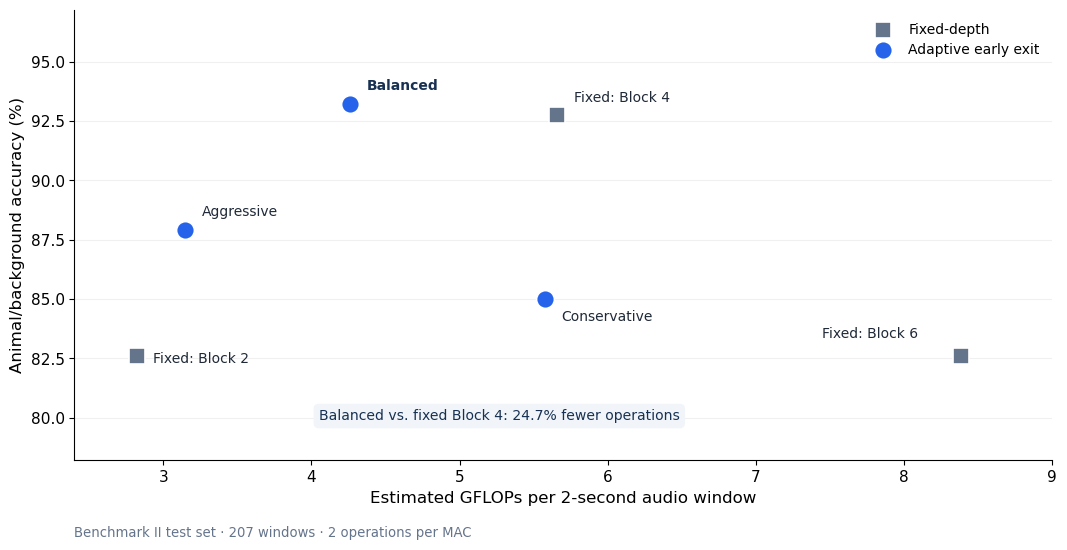

In [3]:
df = read_csv("panns_audio_static_vs_adaptive_2p0s.csv")
required = {"split", "type", "model", "accuracy", "gflops_est"}
assert required.issubset(df), f"Missing PANNs result fields: {sorted(required-set(df.columns))}"
df = df.loc[df.split.eq(AUDIO_SPLIT)].copy()
static_names = {"Exit 1 / block 2": "Fixed: Block 2",
                "Exit 2 / block 4": "Fixed: Block 4",
                "Final / block 6": "Fixed: Block 6"}
adaptive_names = {"aggressive": "Aggressive", "balanced": "Balanced",
                  "conservative": "Conservative"}
df = df.loc[((df.type == "static") & df.model.isin(static_names)) |
            ((df.type == "adaptive") & df.model.isin(adaptive_names))].copy()
if len(df) != 6:
    raise ValueError(f"Expected 3 fixed and 3 adaptive policies; found {len(df)}.")

fig, ax = plt.subplots(figsize=(10.8, 5.6))
for kind, color, marker, legend in [
    ("static", GREY, "s", "Fixed-depth"),
    ("adaptive", BLUE, "o", "Adaptive early exit")]:
    part = df.loc[df.type.eq(kind)]
    ax.scatter(part.gflops_est, part.accuracy * 100, s=125 if kind=="static" else 165,
               marker=marker, c=color, edgecolor="white", linewidth=1.2,
               label=legend, zorder=5)

offsets = {"Exit 1 / block 2": (12,-5), "Exit 2 / block 4": (12,10),
           "Final / block 6": (-100,13), "aggressive": (12,10),
           "balanced": (12,10), "conservative": (12,-16)}
for r in df.itertuples():
    label = static_names.get(r.model, adaptive_names.get(r.model, str(r.model)))
    ax.annotate(label, (r.gflops_est, 100*r.accuracy), xytext=offsets[r.model],
                textcoords="offset points", color=NAVY if r.model=="balanced" else DARK,
                fontsize=10, weight="bold" if r.model=="balanced" else "normal")

b = df.loc[df.model.eq("balanced")].iloc[0]
f = df.loc[df.model.eq("Exit 2 / block 4")].iloc[0]
saving = 100 * (1 - b.gflops_est/f.gflops_est)
ax.text(4.05, 79.9, f"Balanced vs. fixed Block 4: {saving:.1f}% fewer operations",
        color=NAVY, fontsize=10.1,
        bbox={"boxstyle":"round,pad=0.38", "fc":"#F1F5F9", "ec":"none"})
ax.set(xlabel="Estimated GFLOPs per 2-second audio window",
       ylabel="Animal/background accuracy (%)", xlim=(2.4,9.0), ylim=(78.2,97.2))
clean(ax)
ax.legend(frameon=False, loc="upper right", fontsize=10)
ax.text(0.0, -0.17, "Benchmark II test set · 207 windows · 2 operations per MAC",
        transform=ax.transAxes, fontsize=9.5, color=GREY)
fig.tight_layout()
save_pdf(fig, "slide07_panns_accuracy_vs_gflops.pdf")

Saved: Audio\results\presentation_figures\slide09_audio_vs_video_compute.pdf


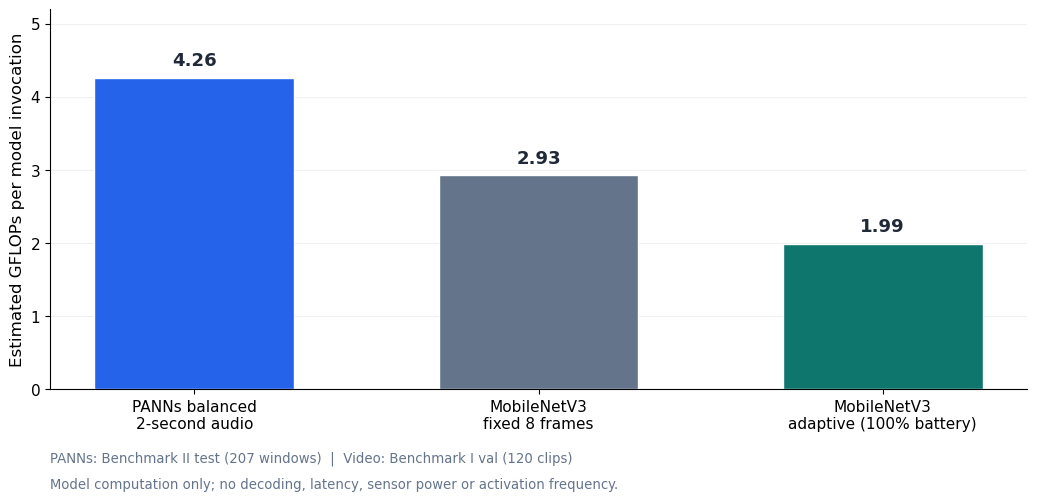

Video source: Audio\results\video_activity_pareto\video_activity_pareto_val_120.csv


In [4]:
panns = read_csv("panns_audio_policy_flops_2p0s.csv")
pann_rows = panns.loc[panns.split.eq(AUDIO_SPLIT) & panns.operating_point.eq("balanced")]
if len(pann_rows) != 1:
    raise ValueError("A single balanced PANNs policy is required.")
audio_gflops = float(pann_rows.iloc[0].expected_audio_gflops)

video_dir = RESULTS / "video_activity_pareto"
video_files = list(video_dir.glob(f"video_activity_pareto_{VIDEO_SPLIT}_*.csv"))
if not video_files:
    raise FileNotFoundError(
        "Video Pareto metrics are unavailable. Expected Audio/results/video_activity_pareto/"
        f"video_activity_pareto_{VIDEO_SPLIT}_<N>.csv, exported by Video_Activity_Battery_Pareto.ipynb."
    )

def video_sample_count(path):
    match = re.search(r"_(\d+)\.csv$", path.name)
    return int(match.group(1)) if match else 0

video_path = max(video_files, key=lambda p: (video_sample_count(p), p.stat().st_mtime_ns))
video = pd.read_csv(video_path)
video_required = {"policy", "battery_pct", "frame_cap", "avg_video_gflops_est", "samples"}
if not video_required.issubset(video):
    raise ValueError(f"Video Pareto CSV lacks: {sorted(video_required-set(video.columns))}")
fixed = video.loc[video.policy.eq("fixed_8_frames")]
adaptive = video.loc[video.policy.eq("battery_example") &
                     video.battery_pct.eq(100) & video.frame_cap.eq(8)]
if len(fixed) != 1 or len(adaptive) != 1:
    raise ValueError("Video result must contain fixed_8_frames and 100% battery_example (8-frame cap).")
video_fixed = float(fixed.iloc[0].avg_video_gflops_est)
video_adaptive = float(adaptive.iloc[0].avg_video_gflops_est)
video_n = int(adaptive.iloc[0]["samples"])

labels = ["PANNs balanced\n2-second audio", "MobileNetV3\nfixed 8 frames",
          "MobileNetV3\nadaptive (100% battery)"]
values = [audio_gflops, video_fixed, video_adaptive]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
bars = ax.bar(range(3), values, width=0.58, color=[BLUE,GREY,TEAL], edgecolor="white")
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.11, f"{val:.2f}",
            ha="center", va="bottom", fontsize=13, weight="bold", color=DARK)
ax.set_xticks(range(3), labels)
ax.set(ylabel="Estimated GFLOPs per model invocation", ylim=(0, max(values)*1.22))
clean(ax)
ax.text(0.0, -0.19,
        f"PANNs: Benchmark II {AUDIO_SPLIT} (207 windows)  |  Video: Benchmark I {VIDEO_SPLIT} ({video_n} clips)",
        fontsize=9.6, color=GREY, transform=ax.transAxes)
ax.text(0.0, -0.26, "Model computation only; no decoding, latency, sensor power or activation frequency.",
        fontsize=9.5, color=GREY, transform=ax.transAxes)
fig.tight_layout()
save_pdf(fig, "slide09_audio_vs_video_compute.pdf")
print("Video source:", video_path.relative_to(ROOT))

Saved: Audio\results\presentation_figures\slide10_audio_gate_detection_comparison.pdf


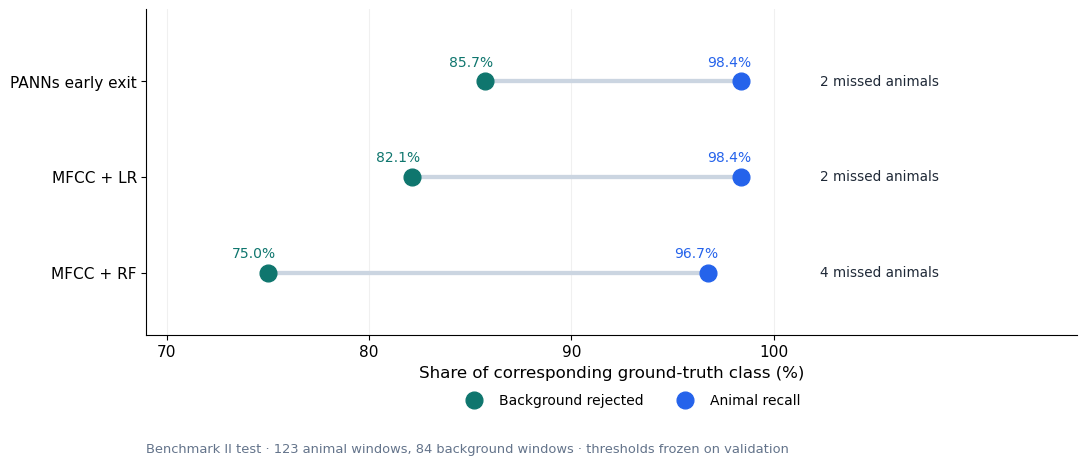

In [5]:
panns = read_csv("panns_early_exit_policy_results_2p0s.csv")
gate = read_csv("mfcc_gate/mfcc_lr_rf_metrics_val_test.csv")
panns = panns.loc[panns.split.eq(AUDIO_SPLIT) & panns.operating_point.eq("balanced")]
gate = gate.loc[gate.split.eq(AUDIO_SPLIT) & gate.model.isin(["MFCC + LR", "MFCC + RF"])]
if len(panns) != 1 or len(gate) != 2:
    raise ValueError("Expected balanced PANNs and both MFCC models for the selected audio split.")
models = ["PANNs early exit", "MFCC + LR", "MFCC + RF"]
recalls = [float(panns.iloc[0].animal_recall)] + [
    float(gate.loc[gate.model.eq(m)].iloc[0].animal_recall) for m in models[1:]]
background = [float(panns.iloc[0].background_rejection)] + [
    float(gate.loc[gate.model.eq(m)].iloc[0].background_rejection) for m in models[1:]]
misses = [int(panns.iloc[0]["fn"])] + [
    int(gate.loc[gate.model.eq(m)].iloc[0]["fn"]) for m in models[1:]]

fig, ax = plt.subplots(figsize=(11.0,5.0))
y = np.arange(len(models))[::-1]
for i, (a,b) in enumerate(zip(recalls,background)):
    ax.plot([100*b,100*a], [y[i], y[i]], color="#CBD5E1", linewidth=3.1, zorder=1)
ax.scatter(100*np.array(background), y, c=TEAL, s=145, label="Background rejected", zorder=4)
ax.scatter(100*np.array(recalls), y, c=BLUE, s=145, label="Animal recall", zorder=4)
for i,(a,b,fn) in enumerate(zip(recalls,background,misses)):
    ax.annotate(f"{100*b:.1f}%", (100*b,y[i]), xytext=(-10,11),
                textcoords="offset points", ha="center", fontsize=10, color=TEAL)
    ax.annotate(f"{100*a:.1f}%", (100*a,y[i]), xytext=(-8,11),
                textcoords="offset points", ha="center", fontsize=10, color=BLUE)
    ax.text(102.3, y[i], f"{fn} missed animals", va="center", fontsize=9.8, color=DARK)
ax.set_yticks(y, models)
ax.set_xlim(69,115)
ax.set_ylim(-0.65,2.75)
ax.set_xticks([70,80,90,100])
ax.set_xlabel("Share of corresponding ground-truth class (%)")
clean(ax, grid_axis="x")
ax.legend(loc="lower center", bbox_to_anchor=(0.52,-0.26), ncol=2,
          frameon=False, fontsize=10)
ax.text(0.0,-0.36, "Benchmark II test · 123 animal windows, 84 background windows · thresholds frozen on validation",
        transform=ax.transAxes, fontsize=9.4, color=GREY)
fig.tight_layout()
save_pdf(fig, "slide10_audio_gate_detection_comparison.pdf")